# P4c — Clinical BERT Models (M3 and M4)

## 1. Introduction and Objective

In Notebook 04b, both TF-IDF models achieved modest improvements over the regex baseline, with the best validation F1 score reaching 0.6960. These results suggest that simple lexical patterns already capture a substantial portion of the predictive information in ED chief complaints. I now examine whether pretrained contextual representations can provide additional predictive value.

Inspired by the application of contextual language models to ED chief complaint classification by Chang et al. (2020), I use Bio_ClinicalBERT (Alsentzer et al., 2019) to develop two classifiers. M3 uses frozen BERT embeddings as input to an L2-regularized logistic regression classifier, while M4 fine-tunes the pretrained BERT model directly on the LBP classification task.

By using the same pretrained checkpoint and experimental partitions, I examine how frozen feature extraction and task-specific fine-tuning perform relative to each other and to the lexical models developed in the previous notebooks.

## 2. Development Dataset Preparation

I use the same modeling dataset and fixed patient-grouped partitions as in the previous notebooks to ensure a consistent comparison across models.

Both M3 and M4 use the cleaned chief complaint text as input and the ICD-derived binary LBP label as the prediction target. The training set is used for model development, and the validation set is used for model selection and classification threshold selection. The test set remains held out for the final comparative evaluation.

In [1]:
from pathlib import Path
import pandas as pd

# Set the data directory for the current environment
DATA_DIR = Path("../results/03_experimental_setup")

# Load the modeling dataset and fixed partition assignments
df = pd.read_csv(
    DATA_DIR / "modeling_dataset.csv",
    keep_default_na=False
)

splits = pd.read_csv(DATA_DIR / "dataset_splits.csv")

# Retain development partitions only
dev_splits = splits[splits["split"].isin(["train", "validation"])]

dev_df = df.merge(
    dev_splits,
    on="stay_id",
    how="inner",
    validate="one_to_one"
)

train_df = dev_df[dev_df["split"] == "train"].copy().reset_index(drop=True)
val_df = dev_df[dev_df["split"] == "validation"].copy().reset_index(drop=True)

# Prepare model inputs and reference labels
X_train = train_df["chiefcomplaint_clean"]
y_train = train_df["lbp_label"]

X_val = val_df["chiefcomplaint_clean"]
y_val = val_df["lbp_label"]

# Check input integrity
assert len(dev_df) == len(dev_splits)
assert dev_df["chiefcomplaint_clean"].notna().all()
assert dev_df["chiefcomplaint_clean"].str.strip().ne("").all()
assert dev_df["lbp_label"].isin([0, 1]).all()

# Summarize development partitions
summary = dev_df.groupby("split").agg(
    encounters=("stay_id", "size"),
    patients=("subject_id", "nunique"),
    positives=("lbp_label", "sum")
)

summary["negatives"] = summary["encounters"] - summary["positives"]
summary["prevalence (%)"] = (
    summary["positives"] / summary["encounters"] * 100
).round(2)

display(summary)

,encounters,patients,positives,negatives,prevalence (%)
split,,,,,
train,295877,143119,11429,284448,3.86
validation,42268,20483,1632,40636,3.86


## 3. Clinical BERT Configuration and Pilot

I use the pretrained Bio_ClinicalBERT checkpoint and its original tokenizer for both M3 and M4. Given the short length of ED chief complaints, I set the maximum sequence length to 64 tokens and use dynamic padding during batch processing to avoid unnecessary computation.

To support execution across different computing environments, I automatically select CUDA, MPS, or CPU based on device availability. Before processing the full dataset, I run a small pilot to verify tokenization, model output dimensions, and computational feasibility.

In [2]:
import random
import numpy as np
import torch
import transformers
from time import perf_counter
from transformers import AutoTokenizer, AutoModel

# Set random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Select the available computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Enable mixed precision on CUDA
use_fp16 = device.type == "cuda"

print(f"PyTorch version: {torch.__version__}")
print(f"Transformers version: {transformers.__version__}")
print(f"Device: {device}")
print(f"FP16 mixed precision: {use_fp16}")

if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.15.0
Transformers version: 5.24.1
Device: mps
FP16 mixed precision: False


In [4]:
# Shared model configuration
MODEL_NAME = "emilyalsentzer/Bio_ClinicalBERT"
MAX_LENGTH = 64
BATCH_SIZE = 32

# Load the pretrained tokenizer and encoder
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device)

# Freeze the encoder for M3
encoder.requires_grad_(False)
encoder.eval()

# Summarize model configuration
print(f"Checkpoint: {MODEL_NAME}")
print(f"Vocabulary size: {len(tokenizer):,}")
print(f"Hidden size: {encoder.config.hidden_size}")
print(f"Maximum sequence length: {MAX_LENGTH}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Total parameters: {sum(p.numel() for p in encoder.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in encoder.parameters() if p.requires_grad):,}")

W1127 12:43:58.186000 2941 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Checkpoint: emilyalsentzer/Bio_ClinicalBERT
Vocabulary size: 28,996
Hidden size: 768
Maximum sequence length: 64
Batch size: 32
Total parameters: 108,310,272
Trainable parameters: 0


In [5]:
from contextlib import nullcontext

# Synthetic examples for the initial sanity check
sample_texts = [
    "back pain",
    "lower back pain",
    "LBP",
    "abdominal pain",
    "severe back pain after a fall"
]

# Tokenize with dynamic padding
inputs = tokenizer(
    sample_texts,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

inputs = {k: v.to(device) for k, v in inputs.items()}

# Run a forward pass through the frozen encoder
with torch.inference_mode():
    with torch.autocast("cuda", dtype=torch.float16) if use_fp16 else nullcontext():
        outputs = encoder(**inputs)

    cls_embeddings = outputs.last_hidden_state[:, 0, :]

# Check output dimensions
print(f"Tokenized input shape: {inputs['input_ids'].shape}")
print(f"Hidden state shape: {outputs.last_hidden_state.shape}")
print(f"CLS embedding shape: {cls_embeddings.shape}")

assert cls_embeddings.shape == (len(sample_texts), encoder.config.hidden_size)
assert torch.isfinite(cls_embeddings).all().item()

print("Forward pass sanity check: PASSED")

Tokenized input shape: torch.Size([5, 8])
Hidden state shape: torch.Size([5, 8, 768])
CLS embedding shape: torch.Size([5, 768])
Forward pass sanity check: PASSED


In [6]:
# Select a small sample from the training set
pilot_texts = X_train.sample(
    n=1024,
    random_state=SEED
).tolist()

def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

# Measure embedding extraction throughput
synchronize_device()
start = perf_counter()

with torch.inference_mode():
    for i in range(0, len(pilot_texts), BATCH_SIZE):
        batch = pilot_texts[i:i + BATCH_SIZE]

        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.autocast("cuda", dtype=torch.float16) if use_fp16 else nullcontext():
            outputs = encoder(**inputs)

        embeddings = outputs.last_hidden_state[:, 0, :].float().cpu()

synchronize_device()
elapsed = perf_counter() - start

throughput = len(pilot_texts) / elapsed
estimated_minutes = (len(X_train) + len(X_val)) / throughput / 60

print(f"Pilot samples: {len(pilot_texts):,}")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Throughput: {throughput:.1f} encounters/second")
print(f"Estimated full embedding extraction: {estimated_minutes:.1f} minutes")

Pilot samples: 1,024
Elapsed time: 1.56 seconds
Throughput: 656.7 encounters/second
Estimated full embedding extraction: 8.6 minutes


The initial sanity check confirms that the frozen Bio_ClinicalBERT encoder produces a 768-dimensional CLS embedding for each chief complaint. The runtime pilot processes 1,024 training encounters in 1.56 seconds on Apple MPS, achieving approximately 657 encounters per second. Based on this observed throughput, full embedding extraction for the training and validation sets is estimated to take approximately 9 minutes. This suggests that local GPU execution is feasible for M3.

## 4. M3 — Frozen Clinical BERT

### 4.1 Embedding Extraction

For M3, I use Bio_ClinicalBERT as a fixed feature extractor without updating its pretrained weights. Each chief complaint is represented by the final-layer CLS embedding, resulting in a 768-dimensional feature vector.

I define a reusable batch extraction function that preserves the original encounter order and uses the tokenizer and model configuration established in Section 3. The extracted embeddings will also be reused in the training data efficiency experiment, since the frozen encoder does not learn from the labeled training data.

In [7]:
from tqdm import tqdm

def extract_embeddings(texts, batch_size=BATCH_SIZE):
    texts = list(texts)
    n_samples = len(texts)
    hidden_size = encoder.config.hidden_size

    # Preallocate the embedding matrix
    all_embeddings = np.empty(
        (n_samples, hidden_size),
        dtype=np.float32
    )

    encoder.eval()

    # Extract embeddings without updating model weights
    with torch.inference_mode():
        for i in tqdm(
            range(0, n_samples, batch_size),
            desc="Extracting embeddings"
        ):
            batch = texts[i:i + batch_size]

            inputs = tokenizer(
                batch,
                padding=True,
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt"
            )

            inputs = {
                k: v.to(device)
                for k, v in inputs.items()
            }

            with torch.autocast(
                "cuda", dtype=torch.float16
            ) if use_fp16 else nullcontext():
                outputs = encoder(**inputs)

            # Extract final-layer CLS embeddings
            batch_embeddings = (
                outputs.last_hidden_state[:, 0, :]
                .float()
                .cpu()
                .numpy()
            )

            all_embeddings[i:i + len(batch)] = batch_embeddings

    return all_embeddings

### 4.2 Embedding Preparation

I apply the frozen encoder to the training and validation sets separately, using the embedding extraction function defined above. I verify the dimensions and numerical validity of the resulting embedding matrices and save them locally together with their encounter identifiers and reference labels.

Caching these embeddings avoids repeated computation during logistic regression model selection and the subsequent training data efficiency experiment. The test set remains held out.

In [8]:
start = perf_counter()

# Extract training embeddings
print("Extracting training embeddings...")
X_train_emb = extract_embeddings(X_train)

# Extract validation embeddings
print("Extracting validation embeddings...")
X_val_emb = extract_embeddings(X_val)

elapsed = perf_counter() - start

print(f"\nTraining embeddings: {X_train_emb.shape}")
print(f"Validation embeddings: {X_val_emb.shape}")
print(f"Total extraction time: {elapsed / 60:.2f} minutes")

Extracting training embeddings...


Extracting embeddings: 100%|██████████| 9247/9247 [09:02<00:00, 17.05it/s]


Extracting validation embeddings...


Extracting embeddings: 100%|██████████| 1321/1321 [01:30<00:00, 14.55it/s]


Training embeddings: (295877, 768)
Validation embeddings: (42268, 768)
Total extraction time: 10.55 minutes


In [9]:
# Verify dimensions and numerical validity
assert X_train_emb.shape == (len(train_df), 768)
assert X_val_emb.shape == (len(val_df), 768)

assert np.isfinite(X_train_emb).all()
assert np.isfinite(X_val_emb).all()

# Verify encounter identifiers
assert train_df["stay_id"].is_unique
assert val_df["stay_id"].is_unique

assert set(train_df["stay_id"]).isdisjoint(
    set(val_df["stay_id"])
)

# Summarize embedding matrices
embedding_summary = pd.DataFrame({
    "encounters": [len(X_train_emb), len(X_val_emb)],
    "embedding_dimensions": [
        X_train_emb.shape[1],
        X_val_emb.shape[1]
    ],
    "dtype": [
        str(X_train_emb.dtype),
        str(X_val_emb.dtype)
    ],
    "size_mb": [
        X_train_emb.nbytes / 1e6,
        X_val_emb.nbytes / 1e6
    ]
}, index=["train", "validation"])

display(embedding_summary.round(2))

print("Embedding validation: PASSED")

,encounters,embedding_dimensions,dtype,size_mb
train,295877,768,float32,908.93
validation,42268,768,float32,129.85


Embedding validation: PASSED


In [10]:
OUTPUT_DIR = Path("../results/04c_clinical_bert_models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save embeddings with encounter identifiers and labels
np.savez(
    OUTPUT_DIR / "train_embeddings.npz",
    embeddings=X_train_emb,
    stay_id=train_df["stay_id"].to_numpy(dtype=np.int64),
    labels=y_train.to_numpy(dtype=np.int64)
)

np.savez(
    OUTPUT_DIR / "val_embeddings.npz",
    embeddings=X_val_emb,
    stay_id=val_df["stay_id"].to_numpy(dtype=np.int64),
    labels=y_val.to_numpy(dtype=np.int64)
)

print("Training and validation embeddings saved.")

Training and validation embeddings saved.


The frozen encoder successfully generated 768-dimensional CLS embeddings for all 338,145 development encounters in 10.55 minutes on Apple MPS. Both embedding matrices passed the dimensional and numerical validity checks and were saved locally with their corresponding encounter identifiers and reference labels. These cached embeddings will be reused for logistic regression model selection and the subsequent training data efficiency experiment.

### 4.3 Logistic Regression Configuration

Unlike the sparse TF-IDF representations used in M1 and M2, Clinical BERT produces dense contextual embeddings. For M3, I use L2-regularized logistic regression to learn a classifier from these fixed representations.

I retain the same balanced class weighting, regularization search space, and classification threshold grid used in the previous notebook. The regularization parameter and classification threshold will be selected jointly based on positive-class F1 on the validation set.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import f1_score

# M3 classifier configuration
m3_classifier = LogisticRegression(
    l1_ratio=0.0,
    solver="lbfgs",
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED
)

# Regularization and threshold candidates
C_GRID = [0.1, 1, 10]
THRESHOLD_GRID = [i / 100 for i in range(5, 100, 5)]

print("M3 classifier configuration:")
print(m3_classifier)

print(f"\nC candidates: {C_GRID}")
print(f"Threshold candidates: {THRESHOLD_GRID}")

M3 classifier configuration:
LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

C candidates: [0.1, 1, 10]
Threshold candidates: [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]


### 4.4 Model Training and Selection

Following the model selection procedure in Notebook 04b, I train an independent logistic regression classifier for each regularization candidate using the frozen training embeddings. For each fitted classifier, I evaluate the predefined classification threshold grid on the validation set.

The combination of C and classification threshold that achieves the highest positive-class validation F1 is selected. Ties are resolved by preferring a smaller C and, within the same C, a higher threshold. The selected fitted classifier is retained without refitting.

In [12]:
m3_candidates = {}
m3_records = []

for C in C_GRID:
    print(f"Training M3 with C={C}...", flush=True)
    start = perf_counter()

    # Train an independent classifier for each C
    clf = clone(m3_classifier).set_params(C=C)
    clf.fit(X_train_emb, y_train)

    # Retain the fitted classifier
    m3_candidates[C] = clf

    # Generate validation prediction scores
    val_probs = clf.predict_proba(X_val_emb)[:, 1]

    # Evaluate classification thresholds
    for threshold in THRESHOLD_GRID:
        val_pred = (val_probs >= threshold).astype(int)

        m3_records.append({
            "C": C,
            "threshold": threshold,
            "f1": f1_score(
                y_val,
                val_pred,
                zero_division=0
            )
        })

    elapsed = perf_counter() - start

    print(f"Completed in {elapsed:.2f} seconds")
    print(f"Iterations: {clf.n_iter_[0]}/{clf.max_iter}")

m3_search_results = pd.DataFrame(m3_records)

Training M3 with C=0.1...
Completed in 15.62 seconds
Iterations: 353/1000
Training M3 with C=1...
Completed in 24.92 seconds
Iterations: 579/1000
Training M3 with C=10...
Completed in 25.09 seconds
Iterations: 580/1000


In [14]:
# Rank candidates using the predefined selection criteria
m3_search_results = m3_search_results.sort_values(
    by=["f1", "C", "threshold"],
    ascending=[False, True, False]
).reset_index(drop=True)

# Summarize the best threshold for each C
m3_selection_summary = (
    m3_search_results
    .drop_duplicates(subset="C")
    .sort_values("C")
    .reset_index(drop=True)
)

display(m3_selection_summary.round(4))

# Select the best configuration
m3_best = m3_search_results.iloc[0]

m3_best_C = float(m3_best["C"])
m3_best_threshold = float(m3_best["threshold"])
m3_best_f1 = float(m3_best["f1"])

# Retain the selected fitted classifier
m3_model = m3_candidates[m3_best_C]

print("Selected M3 configuration:")
print(f"Best C: {m3_best_C}")
print(f"Best threshold: {m3_best_threshold:.2f}")
print(f"Validation F1: {m3_best_f1:.4f}")
print(f"Iterations: {m3_model.n_iter_[0]}/{m3_model.max_iter}")

,C,threshold,f1
0,0.1,0.9,0.6907
1,1.0,0.9,0.6863
2,10.0,0.9,0.6854


Selected M3 configuration:
Best C: 0.1
Best threshold: 0.90
Validation F1: 0.6907
Iterations: 353/1000


Among the three regularization candidates, C = 0.1 achieved the highest validation F1 of 0.6907 at a classification threshold of 0.90. All three candidates completed training within the specified iteration limit.

The selected M3 model outperformed the regex baseline but did not exceed either TF-IDF model in validation F1. This suggests that frozen clinical language representations do not necessarily provide additional predictive value over lexical representations for this short-text classification task. I examine whether task-specific fine-tuning can improve performance in the next section.

## 5. M4 — Fine-tuned Clinical BERT

### 5.1 Model Configuration

While M3 uses Clinical BERT as a frozen feature extractor, M4 updates the pretrained encoder and classification head through supervised learning. This allows the model to adapt its contextual representations to the ICD-defined LBP classification task.

I use the same pretrained checkpoint and tokenizer as M3, with a binary classification head. To account for class imbalance, I use weighted cross-entropy loss. The model is trained using AdamW with two learning rate candidates and three epochs per candidate. Model and classification threshold selection are based on positive-class F1 on the validation set.

In [15]:
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW

# Fine-tuning configuration
NUM_LABELS = 2
LR_GRID = [2e-5, 1e-4]
NUM_EPOCHS = 3
WEIGHT_DECAY = 0.01
TRAIN_BATCH_SIZE = 32

# Initialize an independent model from the pretrained checkpoint
def initialize_m4_model():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=NUM_LABELS
    )

    return model.to(device)

# Display fine-tuning configuration
m4_config = {
    "checkpoint": MODEL_NAME,
    "num_labels": NUM_LABELS,
    "max_length": MAX_LENGTH,
    "learning_rates": LR_GRID,
    "epochs": NUM_EPOCHS,
    "batch_size": TRAIN_BATCH_SIZE,
    "weight_decay": WEIGHT_DECAY,
    "optimizer": "AdamW",
    "device": str(device),
    "fp16": use_fp16,
    "seed": SEED
}

display(pd.Series(m4_config, name="M4 Configuration"))

checkpoint        emilyalsentzer/Bio_ClinicalBERT
num_labels                                      2
max_length                                     64
learning_rates                  [0.00002, 0.0001]
epochs                                          3
batch_size                                     32
weight_decay                                 0.01
optimizer                                   AdamW
device                                        mps
fp16                                        False
seed                                           42
Name: M4 Configuration, dtype: object

### 5.2 Dataset and DataLoader

I prepare the existing training and validation partitions for supervised BERT fine-tuning using PyTorch datasets and data loaders. Chief complaints are tokenized in batches with dynamic padding and a maximum sequence length of 64 tokens.

Training batches are shuffled, while validation batches preserve the original encounter order. To address class imbalance, I calculate balanced class weights using only the training labels. These weights will be used in the cross-entropy loss function during fine-tuning.

In [16]:
from torch.utils.data import Dataset, DataLoader

class ChiefComplaintDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = list(labels)

        assert len(self.texts) == len(self.labels)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return {
            "text": self.texts[idx],
            "label": int(self.labels[idx])
        }


# Tokenize and dynamically pad each batch
def collate_batch(batch):
    texts = [item["text"] for item in batch]
    labels = [item["label"] for item in batch]

    inputs = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    inputs["labels"] = torch.tensor(
        labels,
        dtype=torch.long
    )

    return inputs


# Create development datasets
train_dataset = ChiefComplaintDataset(X_train, y_train)
val_dataset = ChiefComplaintDataset(X_val, y_val)

print(f"Training dataset: {len(train_dataset):,}")
print(f"Validation dataset: {len(val_dataset):,}")

Training dataset: 295,877
Validation dataset: 42,268


In [17]:
def create_dataloaders(batch_size=TRAIN_BATCH_SIZE, seed=SEED):

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate_batch,
        generator=generator,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_batch,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    return train_loader, val_loader


train_loader, val_loader = create_dataloaders()

print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")

# Inspect batch dimensions without displaying clinical text
sample_batch = next(iter(val_loader))

for key, value in sample_batch.items():
    print(f"{key}: {value.shape}")

Training batches: 9,247
Validation batches: 1,321
input_ids: torch.Size([32, 15])
token_type_ids: torch.Size([32, 15])
attention_mask: torch.Size([32, 15])
labels: torch.Size([32])


In [18]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate balanced weights using training labels only
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train.to_numpy()
)

# Convert weights to a PyTorch tensor
class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

# Summarize class weights
weight_summary = pd.DataFrame({
    "label": [0, 1],
    "training_count": [
        (y_train == 0).sum(),
        (y_train == 1).sum()
    ],
    "class_weight": class_weights
})

display(weight_summary.round(4))

,label,training_count,class_weight
0,0,284448,0.5201
1,1,11429,12.9441


### 5.3 Training and Validation Functions

I define reusable training and validation functions for supervised Clinical BERT fine-tuning. During training, weighted cross-entropy accounts for class imbalance, while AdamW updates both the encoder and classification head. Gradient clipping is applied to improve numerical stability.

After each epoch, the model is evaluated on the fixed validation set. I apply the same classification threshold grid used for the previous supervised models and select the configuration that achieves the highest positive-class validation F1.

In [19]:
from torch import nn

def train_one_epoch(
    model,
    dataloader,
    optimizer,
    criterion,
    scaler
):
    model.train()

    total_loss = 0.0
    total_weight = 0.0

    for batch in tqdm(dataloader, desc="Training"):

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        labels = batch.pop("labels")

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        with torch.autocast(
            "cuda", dtype=torch.float16
        ) if use_fp16 else nullcontext():

            outputs = model(**batch)
            loss = criterion(outputs.logits, labels)

        # Backward pass
        scaler.scale(loss).backward()

        # Gradient clipping
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model parameters
        scaler.step(optimizer)
        scaler.update()

        # Aggregate weighted training loss
        batch_weight = criterion.weight[labels].sum().item()

        total_loss += loss.item() * batch_weight
        total_weight += batch_weight

    return total_loss / total_weight

In [20]:
def predict_m4_probabilities(model, dataloader):

    model.eval()
    all_probs = []

    with torch.inference_mode():

        for batch in tqdm(
            dataloader,
            desc="Validation"
        ):

            batch = {
                k: v.to(device)
                for k, v in batch.items()
                if k != "labels"
            }

            with torch.autocast(
                "cuda", dtype=torch.float16
            ) if use_fp16 else nullcontext():

                outputs = model(**batch)

            # Obtain positive-class probabilities
            probs = torch.softmax(
                outputs.logits.float(),
                dim=1
            )[:, 1]

            all_probs.append(probs.cpu().numpy())

    return np.concatenate(all_probs)

In [21]:
def evaluate_thresholds(y_true, probs):

    assert len(y_true) == len(probs)
    assert np.isfinite(probs).all()

    records = []

    for threshold in THRESHOLD_GRID:

        predictions = (probs >= threshold).astype(int)

        records.append({
            "threshold": threshold,
            "f1": f1_score(
                y_true,
                predictions,
                zero_division=0
            )
        })

    results = pd.DataFrame(records)

    results = results.sort_values(
        by=["f1", "threshold"],
        ascending=[False, False]
    ).reset_index(drop=True)

    return results

### 5.4 Training Pilot

Before full fine-tuning, I run a small training pilot to verify that the forward pass, backward pass, weighted loss, and optimizer updates work correctly on the selected device.

The pilot uses 100 batches from the training set to estimate computational requirements and assess whether the planned batch size is feasible. The pilot model is discarded afterward, and each formal training run starts independently from the original pretrained checkpoint.

In [22]:
from itertools import islice

PILOT_BATCHES = 100

# Initialize a temporary model
pilot_model = initialize_m4_model()

# Configure weighted loss and optimizer
pilot_criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

pilot_optimizer = AdamW(
    pilot_model.parameters(),
    lr=LR_GRID[0],
    weight_decay=WEIGHT_DECAY
)

pilot_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_fp16
)

# Create an independent training data loader
pilot_train_loader, _ = create_dataloaders()

print(f"Device: {device}")
print(f"Batch size: {TRAIN_BATCH_SIZE}")
print(f"Pilot batches: {PILOT_BATCHES}")
print(f"Total parameters: {sum(p.numel() for p in pilot_model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in pilot_model.parameters() if p.requires_grad):,}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Device: mps
Batch size: 32
Pilot batches: 100
Total parameters: 108,311,810
Trainable parameters: 108,311,810


In [24]:
# Limit the pilot to the first 100 shuffled training batches
pilot_batches = islice(
    pilot_train_loader,
    PILOT_BATCHES
)

synchronize_device()
start = perf_counter()

pilot_loss = train_one_epoch(
    model=pilot_model,
    dataloader=pilot_batches,
    optimizer=pilot_optimizer,
    criterion=pilot_criterion,
    scaler=pilot_scaler
)

synchronize_device()
elapsed = perf_counter() - start

pilot_samples = PILOT_BATCHES * TRAIN_BATCH_SIZE
throughput = pilot_samples / elapsed

assert np.isfinite(pilot_loss)

print(f"\nPilot batches: {PILOT_BATCHES}")
print(f"Pilot encounters: {pilot_samples:,}")
print(f"Training loss: {pilot_loss:.4f}")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Throughput: {throughput:.2f} encounters/second")
print("Training pilot: PASSED")

Training: 100it [00:27,  3.67it/s]


Pilot batches: 100
Pilot encounters: 3,200
Training loss: 0.6232
Elapsed time: 27.23 seconds
Throughput: 117.53 encounters/second
Training pilot: PASSED


In [25]:
# Estimate runtime based on observed pilot throughput
epoch_seconds = len(train_dataset) / throughput

run_seconds = epoch_seconds * NUM_EPOCHS

total_seconds = run_seconds * len(LR_GRID)

runtime_summary = pd.DataFrame({
    "training_condition": [
        "One epoch",
        "One learning rate (3 epochs)",
        "Both learning rates (6 epochs)"
    ],
    "estimated_minutes": [
        epoch_seconds / 60,
        run_seconds / 60,
        total_seconds / 60
    ],
    "estimated_hours": [
        epoch_seconds / 3600,
        run_seconds / 3600,
        total_seconds / 3600
    ]
})

display(runtime_summary.round(2))

,training_condition,estimated_minutes,estimated_hours
0,One epoch,41.96,0.7
1,One learning rate (3 epochs),125.87,2.1
2,Both learning rates (6 epochs),251.74,4.2


In [26]:
import gc

# Discard the pilot model and optimizer
del pilot_model
del pilot_optimizer
del pilot_criterion
del pilot_scaler
del pilot_batches
del pilot_train_loader

# Release the frozen M3 encoder from GPU memory
encoder.to("cpu")

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()
elif device.type == "mps":
    torch.mps.empty_cache()

print("Pilot resources released.")

Pilot resources released.


The training pilot successfully completed 100 batches (3,200 encounters) on Apple MPS using a batch size of 32.
All 108,311,810 model parameters were trainable, and the weighted training loss remained finite.

The pilot achieved a throughput of 117.53 encounters  per second, corresponding to an estimated training time of approximately 42 minutes per epoch. Based on this 
result, I retain the planned batch size and fine-tuning  configuration for the formal experiments.

### 5.5 Model Training and Selection

Each learning rate candidate is trained independently from the original pretrained checkpoint for three epochs. After each epoch, I evaluate the model on the fixed validation set and search the predefined classification threshold grid.

To preserve intermediate results, I save the training history, threshold search results, and the best-performing model locally. I also retain the most recent training checkpoint so that an interrupted run can resume from the last completed epoch.

The final model is selected based on positive-class validation F1, with ties resolved by preferring a smaller learning rate, an earlier epoch, and a higher classification threshold. No additional refitting is performed after model selection.

#### 5.5.1 Training and Checkpoint Management

I define reusable functions to manage independent training runs and save intermediate results after each epoch. The best-performing model and the most recent training checkpoint are saved separately to support model selection and training resumption. Before starting formal training, I verify the checkpoint saving and loading mechanism through a small smoke test.

In [27]:
import json
import gc

M4_OUTPUT_DIR = OUTPUT_DIR
M4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Save checkpoints without overwriting a valid file
# until the new file has been written successfully
def save_checkpoint(state, path):
    temp_path = path.with_suffix(".tmp")
    torch.save(state, temp_path)
    temp_path.replace(path)


# Capture random states for training resumption
def capture_rng_state(generator):
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "dataloader": generator.get_state()
    }

    if device.type == "cuda":
        state["cuda"] = torch.cuda.get_rng_state_all()
    elif device.type == "mps":
        state["mps"] = torch.mps.get_rng_state()

    return state


# Restore random states after checkpoint loading
def restore_rng_state(state, generator):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    generator.set_state(state["dataloader"])

    if device.type == "cuda":
        torch.cuda.set_rng_state_all(state["cuda"])
    elif device.type == "mps":
        torch.mps.set_rng_state(state["mps"])

In [28]:
def save_run_results(run_dir, history, search_records, best_config):

    # Save epoch-level training history
    pd.DataFrame(history).to_csv(
        run_dir / "training_history.csv",
        index=False
    )

    # Save all validation threshold candidates
    pd.DataFrame(search_records).to_csv(
        run_dir / "threshold_search_results.csv",
        index=False
    )

    # Save the best configuration for this run
    with open(run_dir / "best_config.json", "w") as f:
        json.dump(best_config, f, indent=4)

In [29]:
def train_m4_candidate(learning_rate, resume=False):

    assert learning_rate in LR_GRID

    # Create a separate directory for each learning rate
    run_dir = M4_OUTPUT_DIR / f"m4_lr_{learning_rate:.0e}"
    run_dir.mkdir(parents=True, exist_ok=True)

    last_path = run_dir / "last_checkpoint.pt"
    best_path = run_dir / "best_model.pt"

    if last_path.exists() and not resume:
        raise FileExistsError(
            "Existing checkpoint found. Use resume=True "
            "to continue this training run."
        )

    if resume and not last_path.exists():
        raise FileNotFoundError("No checkpoint available to resume.")

    # Initialize model and training components
    model = initialize_m4_model()

    optimizer = AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights_tensor
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=use_fp16
    )

    train_loader, val_loader = create_dataloaders()

    start_epoch = 1
    history = []
    search_records = []
    best_config = None

    # Restore the last completed epoch if requested
    if resume:

        checkpoint = torch.load(
            last_path,
            map_location="cpu",
            weights_only=False
        )

        assert checkpoint["learning_rate"] == learning_rate

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

        history = checkpoint["history"]
        search_records = checkpoint["search_records"]
        best_config = checkpoint["best_config"]

        start_epoch = checkpoint["epoch"] + 1

        restore_rng_state(
            checkpoint["rng_state"],
            train_loader.generator
        )

        # Recover the best model if saving was interrupted
        if best_config["epoch"] == checkpoint["epoch"]:
            save_checkpoint(
                model.state_dict(),
                best_path
            )

        save_run_results(
            run_dir, history, search_records, best_config
        )

        del checkpoint

        print(f"Resuming from epoch {start_epoch}")

    # Train and validate after each epoch
    for epoch in range(start_epoch, NUM_EPOCHS + 1):

        print(
            f"\nLearning rate: {learning_rate:.0e} | "
            f"Epoch {epoch}/{NUM_EPOCHS}"
        )

        synchronize_device()
        start = perf_counter()

        # Training
        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            scaler
        )

        assert np.isfinite(train_loss)

        synchronize_device()
        train_seconds = perf_counter() - start

        # Validation
        start = perf_counter()

        val_probs = predict_m4_probabilities(
            model,
            val_loader
        )

        threshold_results = evaluate_thresholds(
            y_val,
            val_probs
        )

        val_seconds = perf_counter() - start

        # Retain all threshold search results
        threshold_results["learning_rate"] = learning_rate
        threshold_results["epoch"] = epoch

        search_records.extend(
            threshold_results.to_dict("records")
        )

        # Identify the best threshold for this epoch
        epoch_best = threshold_results.iloc[0]

        epoch_config = {
            "learning_rate": learning_rate,
            "epoch": epoch,
            "threshold": float(epoch_best["threshold"]),
            "f1": float(epoch_best["f1"])
        }

        history.append({
            **epoch_config,
            "training_loss": float(train_loss),
            "training_seconds": train_seconds,
            "validation_seconds": val_seconds
        })

        # Prefer the earlier epoch when F1 is tied
        improved = (
            best_config is None
            or epoch_config["f1"] > best_config["f1"]
        )

        if improved:
            best_config = epoch_config.copy()

        # Save the latest completed training state
        save_checkpoint(
            {
                "learning_rate": learning_rate,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "rng_state": capture_rng_state(
                    train_loader.generator
                ),
                "history": history,
                "search_records": search_records,
                "best_config": best_config
            },
            last_path
        )

        # Save the best-performing model weights
        if improved:
            save_checkpoint(
                model.state_dict(),
                best_path
            )

            print("New best checkpoint saved.")

        # Persist intermediate results
        save_run_results(
            run_dir,
            history,
            search_records,
            best_config
        )

        print(f"Training loss: {train_loss:.4f}")
        print(f"Validation F1: {epoch_config['f1']:.4f}")
        print(f"Best threshold: {epoch_config['threshold']:.2f}")
        print(f"Training time: {train_seconds / 60:.2f} min")
        print(f"Validation time: {val_seconds / 60:.2f} min")
        print(f"Epoch {epoch} results saved.")

    # Release training resources
    del model, optimizer, criterion, scaler
    del train_loader, val_loader

    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()

    return best_config

In [30]:
from tempfile import TemporaryDirectory

# Initialize temporary training components
smoke_model = initialize_m4_model()

smoke_optimizer = AdamW(
    smoke_model.parameters(),
    lr=LR_GRID[0],
    weight_decay=WEIGHT_DECAY
)

smoke_criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

smoke_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_fp16
)

smoke_loader, _ = create_dataloaders()

# Run two batches to initialize optimizer states
smoke_loss = train_one_epoch(
    smoke_model,
    islice(smoke_loader, 2),
    smoke_optimizer,
    smoke_criterion,
    smoke_scaler
)

assert np.isfinite(smoke_loss)

# Test checkpoint saving and loading
with TemporaryDirectory(dir=M4_OUTPUT_DIR) as temp_dir:

    smoke_path = Path(temp_dir) / "smoke_checkpoint.pt"

    save_checkpoint(
        {
            "epoch": 1,
            "model_state_dict": smoke_model.state_dict(),
            "optimizer_state_dict": smoke_optimizer.state_dict(),
            "scaler_state_dict": smoke_scaler.state_dict(),
            "rng_state": capture_rng_state(
                smoke_loader.generator
            )
        },
        smoke_path
    )

    print(f"Checkpoint size: {smoke_path.stat().st_size / 1e6:.2f} MB")

    checkpoint = torch.load(
        smoke_path,
        map_location="cpu",
        weights_only=False
    )

    # Verify saved model weights
    assert all(
        torch.equal(
            param.detach().cpu(),
            checkpoint["model_state_dict"][name]
        )
        for name, param in smoke_model.state_dict().items()
    )

    # Restore training states
    smoke_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    smoke_optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    smoke_scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    restore_rng_state(
        checkpoint["rng_state"],
        smoke_loader.generator
    )

    assert checkpoint["epoch"] == 1

    print("Model state: PASSED")
    print("Optimizer state loading: PASSED")
    print("Scaler state loading: PASSED")
    print("RNG state restoration: PASSED")

# Release temporary resources
del checkpoint
del smoke_model, smoke_optimizer
del smoke_criterion, smoke_scaler, smoke_loader

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()
elif device.type == "mps":
    torch.mps.empty_cache()

print("Checkpoint smoke test: PASSED")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Checkpoint size: 1300.01 MB
Model state: PASSED
Optimizer state loading: PASSED
Scaler state loading: PASSED
RNG state restoration: PASSED
Checkpoint smoke test: PASSED


#### 5.5.2 Independent Training Runs

I train each learning rate candidate independently from the original pretrained checkpoint using the same training data, validation set, and initial random seed.

Training history, validation threshold search results, and model checkpoints are saved after each epoch.

In [31]:
m4_result_lr1 = train_m4_candidate(
    learning_rate=2e-5
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec


Learning rate: 2e-05 | Epoch 1/3


Validation: 100%|██████████| 1321/1321 [01:49<00:00, 12.06it/s]


New best checkpoint saved.
Training loss: 0.5076
Validation F1: 0.6976
Best threshold: 0.85
Training time: 69.68 min
Validation time: 1.83 min
Epoch 1 results saved.

Learning rate: 2e-05 | Epoch 2/3


Validation: 100%|██████████| 1321/1321 [01:34<00:00, 14.05it/s]


Training loss: 0.4741
Validation F1: 0.6957
Best threshold: 0.80
Training time: 72.14 min
Validation time: 1.57 min
Epoch 2 results saved.

Learning rate: 2e-05 | Epoch 3/3


Validation: 100%|██████████| 1321/1321 [01:29<00:00, 14.77it/s]


Training loss: 0.5714
Validation F1: 0.6970
Best threshold: 0.30
Training time: 74.88 min
Validation time: 1.49 min
Epoch 3 results saved.


**Learning Rate = 1e-4 (Google Colab)**

Due to the computational cost of local fine-tuning, I executed the second learning rate candidate in a separate Google Colab notebook (`04c_clinical_bert_models_colab.ipynb`) using an NVIDIA Tesla T4 GPU.

I retained the same training and validation partitions, pretrained checkpoint, batch size, random seed, weighted loss, optimizer configuration, and model selection procedure. FP16 mixed precision was disabled to maintain FP32 precision across both computing environments.

After completing all three epochs, I transferred the model checkpoints, training history, threshold search results, selected configuration, and environment metadata to the local `m4_lr_1e-04` results directory for joint model selection.

#### 5.5.3 Training Results and Model Selection

Both learning rate candidates completed the planned three training epochs.

| Learning Rate | Epoch | Training Loss | Validation F1 | Best Threshold |
|---|---:|---:|---:|---:|
| 2e-5 | 1 | 0.5076 | 0.6976 | 0.85 |
| 2e-5 | 2 | 0.4741 | 0.6957 | 0.80 |
| 2e-5 | 3 | 0.5714 | 0.6970 | 0.30 |
| 1e-4 | 1 | 0.7152 | 0.0744 | 0.50 |
| 1e-4 | 2 | 0.7091 | 0.0744 | 0.40 |
| 1e-4 | 3 | 0.7081 | 0.0744 | 0.50 |

The 2e-5 candidate achieved its highest validation F1 of 0.6976 after the first epoch, with no further improvement in subsequent epochs.

In contrast, the 1e-4 candidate showed little improvement in training loss and achieved a validation F1 of 0.0744 across all three epochs. This value is identical to the F1 of an all-positive classifier on the validation set, suggesting degenerate classification behavior.

Although the higher learning rate may have contributed to unsuccessful fine-tuning, the two candidates were trained using different hardware backends and software versions. Therefore, the observed performance difference cannot be attributed solely to the learning rate.

Following the predefined validation-based selection procedure, I retain the checkpoint from the first epoch of the 2e-5 candidate with a classification threshold of 0.85. No additional refitting is performed.

In [33]:
# Load results from both independent training runs
m4_history = []
m4_search_records = []

for lr in LR_GRID:
    run_dir = M4_OUTPUT_DIR / f"m4_lr_{lr:.0e}"

    history = pd.read_csv(
        run_dir / "training_history.csv"
    )

    search_results = pd.read_csv(
        run_dir / "threshold_search_results.csv"
    )

    # Verify that each training run is complete
    assert len(history) == NUM_EPOCHS
    assert set(history["epoch"]) == set(range(1, NUM_EPOCHS + 1))

    assert len(search_results) == (
        NUM_EPOCHS * len(THRESHOLD_GRID)
    )

    assert np.allclose(history["learning_rate"], lr)
    assert np.allclose(search_results["learning_rate"], lr)

    assert not search_results.duplicated(
        subset=["epoch", "threshold"]
    ).any()

    assert (run_dir / "best_model.pt").exists()

    m4_history.append(history)
    m4_search_records.append(search_results)

# Combine both learning rate candidates
m4_training_history = pd.concat(
    m4_history, ignore_index=True
)

m4_search_results = pd.concat(
    m4_search_records, ignore_index=True
)

assert len(m4_search_results) == 114

display(m4_training_history.round(4))

print(f"Completed epochs: {len(m4_training_history)}")
print(f"Total candidate combinations: {len(m4_search_results)}")
print("Training results validation: PASSED")

,learning_rate,epoch,threshold,f1,training_loss,training_seconds,validation_seconds
0,0.0000,1,0.85,0.6976,0.5076,4180.7695,109.8262
1,0.0000,2,0.80,0.6957,0.4741,4328.5825,94.3121
2,0.0000,3,0.30,0.6970,0.5714,4492.5126,89.5361
3,0.0001,1,0.50,0.0744,0.7152,1106.6295,34.9360
4,0.0001,2,0.40,0.0744,0.7091,1096.4074,34.5776
5,0.0001,3,0.50,0.0744,0.7081,1101.9368,34.5634


Completed epochs: 6
Total candidate combinations: 114
Training results validation: PASSED


In [35]:
# Rank all candidates using the predefined selection criteria
m4_search_results = m4_search_results.sort_values(
    by=["f1", "learning_rate", "epoch", "threshold"],
    ascending=[False, True, True, False]
).reset_index(drop=True)

# Summarize the best configuration for each learning rate
m4_selection_summary = (
    m4_search_results
    .drop_duplicates(subset="learning_rate")
    .sort_values("learning_rate")
    .reset_index(drop=True)
)

display(
    m4_selection_summary.style.format({
        "learning_rate": "{:.0e}",
        "threshold": "{:.2f}",
        "f1": "{:.4f}"
    })
)

# Select the best overall configuration
m4_best = m4_search_results.iloc[0]

m4_best_lr = float(m4_best["learning_rate"])
m4_best_epoch = int(m4_best["epoch"])
m4_best_threshold = float(m4_best["threshold"])
m4_best_f1 = float(m4_best["f1"])

m4_best_dir = (
    M4_OUTPUT_DIR / f"m4_lr_{m4_best_lr:.0e}"
)

m4_best_path = m4_best_dir / "best_model.pt"

# Verify consistency with the saved checkpoint configuration
with open(m4_best_dir / "best_config.json") as f:
    saved_config = json.load(f)

assert saved_config["epoch"] == m4_best_epoch
assert np.isclose(saved_config["learning_rate"], m4_best_lr)
assert np.isclose(saved_config["threshold"], m4_best_threshold)
assert np.isclose(saved_config["f1"], m4_best_f1)

print("Selected M4 configuration:")
print(f"Best learning rate: {m4_best_lr:.0e}")
print(f"Best epoch: {m4_best_epoch}")
print(f"Best threshold: {m4_best_threshold:.2f}")
print(f"Validation F1: {m4_best_f1:.4f}")
print(f"Checkpoint: {m4_best_path.name}")
print("Model selection validation: PASSED")

,threshold,f1,learning_rate,epoch
0,0.85,0.6976,2e-05,1
1,0.50,0.0744,1e-04,1


Selected M4 configuration:
Best learning rate: 2e-05
Best epoch: 1
Best threshold: 0.85
Validation F1: 0.6976
Checkpoint: best_model.pt
Model selection validation: PASSED


## 6. Validation Performance

### 6.1 Generate Validation Predictions

I generate validation predictions using the selected M3 and M4 models and their respective classification thresholds. For M3, I reuse the fitted logistic regression classifier and cached validation embeddings. For M4, I reload the selected model checkpoint. I verify that the resulting validation F1 scores are consistent with the model selection results before computing additional evaluation metrics.

In [36]:
# Generate M3 validation scores and predictions
m3_val_probs = m3_model.predict_proba(X_val_emb)[:, 1]

m3_val_pred = (
    m3_val_probs >= m3_best_threshold
).astype(int)

# Verify prediction validity
assert len(m3_val_probs) == len(y_val)
assert np.isfinite(m3_val_probs).all()

# Verify consistency with model selection
m3_val_f1 = f1_score(
    y_val, m3_val_pred, zero_division=0
)

assert np.isclose(m3_val_f1, m3_best_f1)

print(f"M3 validation predictions: {len(m3_val_pred):,}")
print(f"Validation F1: {m3_val_f1:.4f}")
print("M3 prediction validation: PASSED")

M3 validation predictions: 42,268
Validation F1: 0.6907
M3 prediction validation: PASSED


In [37]:
# Reload the selected M4 checkpoint
m4_model = initialize_m4_model()

m4_model.load_state_dict(
    torch.load(
        m4_best_path,
        map_location="cpu",
        weights_only=True
    )
)

# Generate validation scores and predictions
m4_val_probs = predict_m4_probabilities(
    m4_model,
    val_loader
)

m4_val_pred = (
    m4_val_probs >= m4_best_threshold
).astype(int)

# Verify prediction validity
assert len(m4_val_probs) == len(y_val)
assert np.isfinite(m4_val_probs).all()

# Verify consistency with model selection
m4_val_f1 = f1_score(
    y_val, m4_val_pred, zero_division=0
)

assert np.isclose(m4_val_f1, m4_best_f1)

print(f"M4 validation predictions: {len(m4_val_pred):,}")
print(f"Validation F1: {m4_val_f1:.4f}")
print("M4 prediction validation: PASSED")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

M4 validation predictions: 42,268
Validation F1: 0.6976
M4 prediction validation: PASSED


### 6.2 Compute Evaluation Metrics

Following the evaluation procedure in Notebook 04b, I compute precision, recall, F1, AUROC, average precision, and confusion matrix counts for the selected M3 and M4 models. Precision, recall, F1, and confusion matrix counts are calculated using the selected classification thresholds, while AUROC and average precision are calculated from the continuous positive-class prediction scores.

In [38]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

def compute_validation_metrics(y_true, probs, predictions):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "auroc": roc_auc_score(y_true, probs),
        "average_precision": average_precision_score(
            y_true, probs
        ),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }

In [39]:
# Evaluate selected Clinical BERT models
m3_metrics = compute_validation_metrics(
    y_val,
    m3_val_probs,
    m3_val_pred
)

m4_metrics = compute_validation_metrics(
    y_val,
    m4_val_probs,
    m4_val_pred
)

# Combine validation results
bert_validation_metrics = pd.DataFrame(
    [m3_metrics, m4_metrics],
    index=["M3", "M4"]
)

bert_validation_metrics.index.name = "model"

# Verify confusion matrix counts
for model, row in bert_validation_metrics.iterrows():

    assert row["tn"] + row["fp"] == (y_val == 0).sum()
    assert row["fn"] + row["tp"] == (y_val == 1).sum()

display(bert_validation_metrics.round(4))

print("Validation metrics checks: PASSED")

,precision,recall,f1,auroc,average_precision,tn,fp,fn,tp
model,,,,,,,,,
M3,0.7069,0.6752,0.6907,0.9451,0.6675,40179,457,530,1102
M4,0.6942,0.7010,0.6976,0.9382,0.6827,40132,504,488,1144


Validation metrics checks: PASSED


### 6.3 Comparative Analysis

I combine the validation results from the regex baseline, TF-IDF models, and Clinical BERT models to compare their predictive performance on the same validation set. In addition to positive-class F1, I examine precision, recall, and ranking-based metrics to understand the trade-offs across different NLP approaches. These results describe model development performance rather than final generalization performance, which will be evaluated on the held-out test set.

In [42]:
RESULTS_DIR = Path("../results")

# Load M0 validation results
regex_metrics = pd.read_csv(
    RESULTS_DIR
    / "04a_regex_baseline"
    / "m0_validation_metrics.csv",
    index_col="model"
)

# Standardize the model identifier
regex_metrics = regex_metrics.rename(
    index={"M0 - Regex": "M0"}
)

# Load M1 and M2 validation results
tfidf_metrics = pd.read_csv(
    RESULTS_DIR
    / "04b_tfidf_models"
    / "validation_metrics.csv",
    index_col="model"
)

# Exclude the previously included regex baseline
tfidf_metrics = tfidf_metrics.loc[["M1", "M2"]]

# Standardize the average precision column name
tfidf_metrics = tfidf_metrics.rename(
    columns={"ap": "average_precision"}
)

# Combine validation metrics
all_validation_metrics = pd.concat([
    regex_metrics,
    tfidf_metrics,
    bert_validation_metrics
])

display(all_validation_metrics.round(4))

print("Available models:", all_validation_metrics.index.tolist())
print("Metric columns:", all_validation_metrics.columns.tolist())

,precision,recall,f1,tn,fp,fn,tp,auroc,average_precision
model,,,,,,,,,
M0,0.6686,0.6924,0.6803,40076,560,502,1130,NaN,NaN
M1,0.7145,0.6746,0.6940,40196,440,531,1101,0.9481,0.6591
M2,0.7079,0.6844,0.6960,40175,461,515,1117,0.9476,0.6653
M3,0.7069,0.6752,0.6907,40179,457,530,1102,0.9451,0.6675
M4,0.6942,0.7010,0.6976,40132,504,488,1144,0.9382,0.6827


Available models: ['M0', 'M1', 'M2', 'M3', 'M4']
Metric columns: ['precision', 'recall', 'f1', 'tn', 'fp', 'fn', 'tp', 'auroc', 'average_precision']


In [43]:
EXPECTED_MODELS = ["M0", "M1", "M2", "M3", "M4"]

METRIC_COLUMNS = [
    "precision",
    "recall",
    "f1",
    "auroc",
    "average_precision",
    "tn", "fp", "fn", "tp"
]

# Verify model and metric coverage
assert all_validation_metrics.index.is_unique
assert set(all_validation_metrics.index) == set(EXPECTED_MODELS)
assert set(METRIC_COLUMNS).issubset(
    all_validation_metrics.columns
)

all_validation_metrics = all_validation_metrics.loc[
    EXPECTED_MODELS, METRIC_COLUMNS
]

# Verify consistent validation class counts
assert (
    all_validation_metrics["tn"]
    + all_validation_metrics["fp"]
    == (y_val == 0).sum()
).all()

assert (
    all_validation_metrics["fn"]
    + all_validation_metrics["tp"]
    == (y_val == 1).sum()
).all()

# Verify ranking-based metric availability
ranking_metrics = ["auroc", "average_precision"]

assert all_validation_metrics.loc[
    "M0", ranking_metrics
].isna().all()

assert all_validation_metrics.loc[
    ["M1", "M2", "M3", "M4"], ranking_metrics
].notna().all().all()

display(all_validation_metrics.round(4))

print("Combined validation results: PASSED")

,precision,recall,f1,auroc,average_precision,tn,fp,fn,tp
model,,,,,,,,,
M0,0.6686,0.6924,0.6803,NaN,NaN,40076,560,502,1130
M1,0.7145,0.6746,0.6940,0.9481,0.6591,40196,440,531,1101
M2,0.7079,0.6844,0.6960,0.9476,0.6653,40175,461,515,1117
M3,0.7069,0.6752,0.6907,0.9451,0.6675,40179,457,530,1102
M4,0.6942,0.7010,0.6976,0.9382,0.6827,40132,504,488,1144


Combined validation results: PASSED


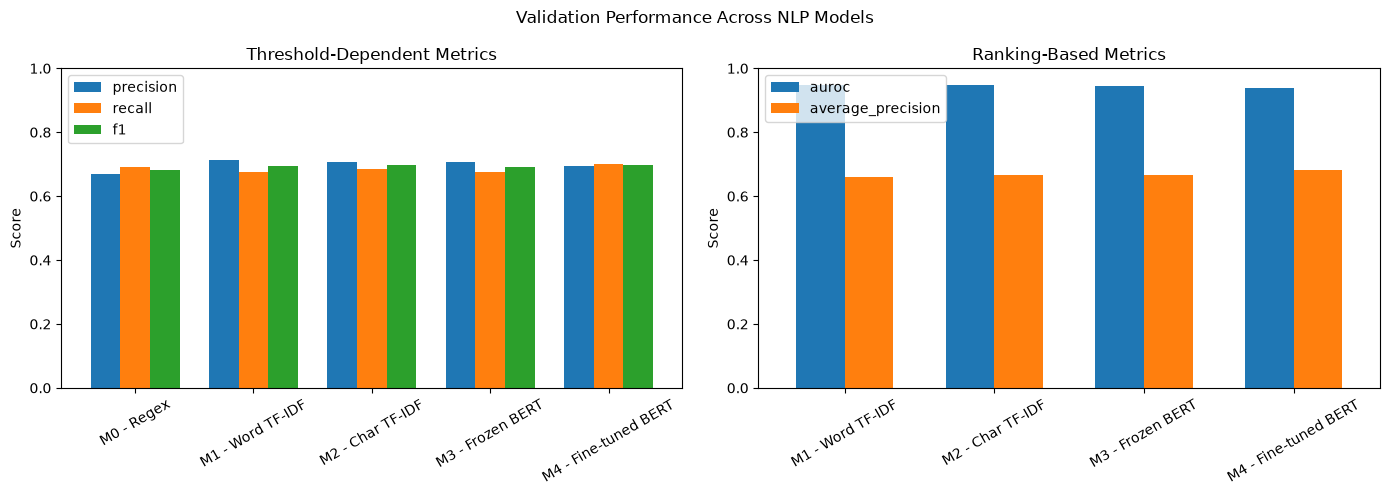

In [44]:
import matplotlib.pyplot as plt

# Define model display names
model_names = {
    "M0": "M0 - Regex",
    "M1": "M1 - Word TF-IDF",
    "M2": "M2 - Char TF-IDF",
    "M3": "M3 - Frozen BERT",
    "M4": "M4 - Fine-tuned BERT"
}

plot_metrics = all_validation_metrics.rename(
    index=model_names
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Threshold-dependent metrics
plot_metrics[["precision", "recall", "f1"]].plot(
    kind="bar",
    ax=axes[0],
    width=0.75
)

axes[0].set_title("Threshold-Dependent Metrics")
axes[0].set_ylabel("Score")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(loc="upper left")

# Ranking-based metrics
plot_metrics[["auroc", "average_precision"]].dropna().plot(
    kind="bar",
    ax=axes[1],
    width=0.65
)

axes[1].set_title("Ranking-Based Metrics")
axes[1].set_ylabel("Score")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(loc="upper left")

fig.suptitle("Validation Performance Across NLP Models")

plt.tight_layout()
plt.show()

The five NLP models achieved validation F1 scores ranging from 0.6803 to 0.6976. Both TF-IDF models outperformed the regex baseline and the frozen Clinical BERT model in F1, demonstrating that lexical representations remain competitive for this short-text classification task.

Fine-tuning Clinical BERT improved F1, recall, and average precision compared with the frozen encoder approach. However, its F1 improvement over character-level TF-IDF was only 0.0016.

No single model performed best across all evaluation metrics. Word-level TF-IDF achieved the highest precision and AUROC, while fine-tuned Clinical BERT achieved the highest recall, F1, and average precision.

These preliminary results suggest that increasing model complexity does not necessarily lead to substantial improvements in predictive performance. The relative performance of these models will be further examined under different training data conditions and on the held-out test set.

## 7. Save Results

I save the selected M3 classifier, model configurations, hyperparameter search results, and validation metrics for subsequent experiments. The M3 embeddings and M4 checkpoints have already been saved during model development and are reused without additional computation.

These artifacts support the training data efficiency experiment and final held-out test evaluation without repeating model training or hyperparameter selection. All model artifacts and intermediate results are stored locally.

In [45]:
import joblib
import sklearn
import transformers

# Save the selected logistic regression classifier
joblib.dump(
    m3_model,
    OUTPUT_DIR / "m3_classifier.joblib"
)

# Save M3 configuration
m3_config = {
    "model_id": "M3",
    "checkpoint": MODEL_NAME,
    "encoder_frozen": True,
    "pooling": "final_layer_cls",
    "embedding_dimensions": 768,
    "max_length": MAX_LENGTH,
    "input_column": "chiefcomplaint_clean",
    "best_C": m3_best_C,
    "best_threshold": m3_best_threshold,
    "validation_f1": m3_best_f1,
    "classifier_params": m3_model.get_params(),
    "seed": SEED,
    "sklearn_version": sklearn.__version__,
    "torch_version": str(torch.__version__),
    "transformers_version": transformers.__version__
}

with open(OUTPUT_DIR / "m3_config.json", "w") as f:
    json.dump(m3_config, f, indent=4)

# Save complete hyperparameter search results
m3_search_results.to_csv(
    OUTPUT_DIR / "m3_selection_results.csv",
    index=False
)

print("M3 model and configuration saved.")

M3 model and configuration saved.


In [46]:
# Record the selected M4 configuration
m4_selected_config = {
    "model_id": "M4",
    "checkpoint": MODEL_NAME,
    "encoder_frozen": False,
    "num_labels": NUM_LABELS,
    "input_column": "chiefcomplaint_clean",
    "max_length": MAX_LENGTH,
    "batch_size": TRAIN_BATCH_SIZE,
    "learning_rate_grid": LR_GRID,
    "planned_epochs": NUM_EPOCHS,
    "best_learning_rate": m4_best_lr,
    "best_epoch": m4_best_epoch,
    "best_threshold": m4_best_threshold,
    "validation_f1": m4_best_f1,
    "optimizer": "AdamW",
    "weight_decay": WEIGHT_DECAY,
    "learning_rate_schedule": "constant",
    "max_grad_norm": 1.0,
    "loss": "weighted_cross_entropy",
    "class_weights": class_weights.tolist(),
    "threshold_grid": THRESHOLD_GRID,
    "checkpoint_path": str(
        m4_best_path.relative_to(OUTPUT_DIR)
    ),
    "seed": SEED,
    "device": str(device),
    "fp16": use_fp16,
    "torch_version": str(torch.__version__),
    "transformers_version": transformers.__version__
}

with open(OUTPUT_DIR / "m4_config.json", "w") as f:
    json.dump(m4_selected_config, f, indent=4)

# Save combined training history
m4_training_history.to_csv(
    OUTPUT_DIR / "m4_training_history.csv",
    index=False
)

# Save complete model selection results
m4_search_results.to_csv(
    OUTPUT_DIR / "m4_selection_results.csv",
    index=False
)

print("M4 selected configuration and training results saved.")

M4 selected configuration and training results saved.


In [47]:
# Save Clinical BERT validation results
bert_validation_metrics.to_csv(
    OUTPUT_DIR / "validation_metrics.csv"
)

# Save cumulative comparison results
all_validation_metrics.to_csv(
    OUTPUT_DIR / "combined_validation_metrics.csv"
)

print("Validation metrics saved.")

Validation metrics saved.


In [48]:
expected_files = [
    "train_embeddings.npz",
    "val_embeddings.npz",
    "m3_classifier.joblib",
    "m3_config.json",
    "m3_selection_results.csv",
    "m4_config.json",
    "m4_training_history.csv",
    "m4_selection_results.csv",
    "validation_metrics.csv",
    "combined_validation_metrics.csv",
    "m4_lr_2e-05/best_model.pt",
    "m4_lr_1e-04/best_model.pt"
]

artifact_records = []

for filename in expected_files:
    path = OUTPUT_DIR / filename

    artifact_records.append({
        "file": filename,
        "exists": path.is_file(),
        "size_mb": (
            path.stat().st_size / 1e6
            if path.is_file() else 0
        )
    })

artifact_summary = pd.DataFrame(artifact_records)

display(artifact_summary.round(4))

assert artifact_summary["exists"].all()
assert (artifact_summary["size_mb"] > 0).all()

print("Artifact validation: PASSED")
print("Notebook 04c: COMPLETED")

,file,exists,size_mb
0,train_embeddings.npz,True,913.6689
1,val_embeddings.npz,True,130.5243
2,m3_classifier.joblib,True,0.0039
3,m3_config.json,True,0.0009
4,m3_selection_results.csv,True,0.0016
5,m4_config.json,True,0.0011
6,m4_training_history.csv,True,0.0006
7,m4_selection_results.csv,True,0.0032
8,validation_metrics.csv,True,0.0003
9,combined_validation_metrics.csv,True,0.0006


Artifact validation: PASSED
Notebook 04c: COMPLETED
